In [1]:
# Session 8.6 — Pandas માં Handling Duplicates & Outliers
# આજે આપણે શીખીશું કે Dataset માં Duplicate Records એટલે કે એકસરખા રેકોર્ડ્સ કેવી રીતે શોધવા અને દૂર કરવા, તેમજ Outliers એટલે કે સામાન્ય Values કરતાં અસામાન્ય રીતે મોટી કે નાની Values ને કેવી રીતે ઓળખવા.

# આ Session Data Cleaning અને Data Science બંને માટે ખૂબ જ ઉપયોગી છે.

# 8.6.1 — Duplicate Values
# duplicated(), drop_duplicates()

# 8.6.2 — Outliers ઓળખવા
# IQR Method, Box Plot Concept

# 8.6.3 — Z-score Concept
# Mean, Standard Deviation અને અસામાન્ય Values

# 1. Duplicate Records એટલે શું?

# English Definition: Duplicate records are rows that repeat the same data, either across all columns or in selected identifying columns.

# ગુજરાતીમાં: Dataset માં એક જ રેકોર્ડ એકથી વધુ વખત નોંધાયેલો હોય, તો તેને Duplicate Record કહેવાય છે.

# ઉદાહરણ તરીકે, કોલેજના Student Registration Dataset માં StudentID 102 બે વખત હોય તો તે Duplicate હોઈ શકે છે.
# StudentID	Name	Department	Marks
# 101	Amit	IT	85
# 102	Neha	CS	92
# 103	Ravi	IT	76
# 102	Neha	CS	92
# 104	Pooja	CS	88

# અહીં Neha નો રેકોર્ડ બે વખત છે.

In [2]:
import pandas as pd
import numpy as np

data = {
    "StudentID": [101, 102, 103, 102, 104, 105, 105],
    "Name": ["Amit", "Neha", "Ravi", "Neha", "Pooja", "Karan", "Karan"],
    "Department": ["IT", "CS", "IT", "CS", "CS", "IT", "IT"],
    "Marks": [85, 92, 76, 92, 88, 67, 67],
    "Fees": [15000, 18000, 15000, 18000, 17000, 16000, 16000]
}

df = pd.DataFrame(data)

print(df)

   StudentID   Name Department  Marks   Fees
0        101   Amit         IT     85  15000
1        102   Neha         CS     92  18000
2        103   Ravi         IT     76  15000
3        102   Neha         CS     92  18000
4        104  Pooja         CS     88  17000
5        105  Karan         IT     67  16000
6        105  Karan         IT     67  16000


In [ ]:
# 3. duplicated() — Duplicate Records શોધવા
# 3.1 સંપૂર્ણ Row Duplicate છે કે નહીં?

print(df.duplicated())

# True aape taya dublicate data che

0    False
1    False
2    False
3     True
4    False
5    False
6     True
dtype: bool


In [ ]:
print(df[df.duplicated()]) # row ma duplicate janava

   StudentID   Name Department  Marks   Fees
3        102   Neha         CS     92  18000
6        105  Karan         IT     67  16000


In [ ]:
print(df[df.duplicated(keep=False)])
# keep=False વાપરવાથી Duplicate Group ની બધી સંબંધિત Rows ચિહ્નિત થાય છે.

   StudentID   Name Department  Marks   Fees
1        102   Neha         CS     92  18000
3        102   Neha         CS     92  18000
5        105  Karan         IT     67  16000
6        105  Karan         IT     67  16000


In [8]:
# 3.3 ચોક્કસ Column ના આધારે Duplicate શોધવા
# ધારો કે StudentID અનન્ય હોવો જોઈએ.

print(df[df.duplicated(subset=["StudentID"],keep=False)])

   StudentID   Name Department  Marks   Fees
1        102   Neha         CS     92  18000
3        102   Neha         CS     92  18000
5        105  Karan         IT     67  16000
6        105  Karan         IT     67  16000


In [9]:
# અહીં StudentID એકસરખો હોય તેવી બધી Rows દેખાશે, ભલે બીજા Columns અલગ હોય.
# keep Parameter
# Code	અર્થ
# df.duplicated()	પ્રથમ Record રાખીને પછીની પુનરાવર્તિત Rows ને True કરે
# df.duplicated(keep="last")	છેલ્લો Record રાખે અને અગાઉની Duplicate Rows ને True કરે
# df.duplicated(keep=False)	Duplicate Group ની બધી Rows ને True કરે



In [ ]:
# 4. drop_duplicates() — Duplicate Rows દૂર કરવી
# 4.1 સંપૂર્ણ Duplicate Rows દૂર કરો

clean_df = df.drop_duplicates()

print(clean_df)

# આઉટપુટમાં Neha અને Karan ના પુનરાવર્તિત રેકોર્ડ્સની બીજી નકલ દૂર થશે.

# મૂળ df બદલાતું નથી; પરિણામ clean_df માં Store થાય છે.

   StudentID   Name Department  Marks   Fees
0        101   Amit         IT     85  15000
1        102   Neha         CS     92  18000
2        103   Ravi         IT     76  15000
4        104  Pooja         CS     88  17000
5        105  Karan         IT     67  16000


In [ ]:
# 4.2 StudentID ના આધારે Duplicate દૂર કરો
# આ Code દરેક StudentID માટે પ્રથમ Record રાખે છે અને ત્યારબાદના Record દૂર કરે છે.

clean_df = df.drop_duplicates(
    subset=["StudentID"],
    keep="first"
)

print(clean_df)

   StudentID   Name Department  Marks   Fees
0        101   Amit         IT     85  15000
1        102   Neha         CS     92  18000
2        103   Ravi         IT     76  15000
4        104  Pooja         CS     88  17000
5        105  Karan         IT     67  16000


In [ ]:
# 4.3 છેલ્લો Record રાખવો
#aama last record rakhava ma aave che

clean_df = df.drop_duplicates(
    subset=["StudentID"],
    keep="last"
)

print(clean_df)

   StudentID   Name Department  Marks   Fees
0        101   Amit         IT     85  15000
2        103   Ravi         IT     76  15000
3        102   Neha         CS     92  18000
4        104  Pooja         CS     88  17000
6        105  Karan         IT     67  16000


In [ ]:
# 4.4 Duplicate દૂર કરતાં પહેલાં અને પછી ગણતરી કરો

print("Before :",len(df)) # phela 7 row che

clean_df = df.drop_duplicates()

print("After :",len(clean_df)) # pachi 5 row che
print("Removed:",len(df) - len(clean_df)) # total ketli reomve

Before : 7
After : 5
Removed: 2


In [14]:
# 5. Outliers એટલે શું?
# English Definition: An outlier is a data point that lies unusually far from the other observations in a dataset.

# ગુજરાતીમાં: Dataset માં એવી Value જે બાકીની Values કરતાં અસામાન્ય રીતે ઘણી મોટી અથવા નાની હોય તેને Outlier કહેવાય છે.

# ઉદાહરણ તરીકે, વિદ્યાર્થીઓના Marks:

# 72, 75, 78, 80, 82, 85, 99

# આ Values માં 99 ઊંચી Value છે, પરંતુ તે જરૂરી નથી કે Outlier જ હોય.

# હવે આ Dataset જુઓ:

# 72, 75, 78, 80, 82, 85, 500

# અહીં 500 સંભવિત Outlier છે, કારણ કે તે બીજા Marks કરતાં ખૂબ અલગ છે. તે Data Entry Error પણ હોઈ શકે છે.

# મહત્વપૂર્ણ: Outlier એટલે હંમેશાં ખોટી Value નહીં. તે સાચી અને ઉપયોગી માહિતી પણ હોઈ શકે છે.

# ઉદાહરણો:
# - આવકના Dataset માં ખૂબ ઊંચી આવક ધરાવતી વ્યક્તિ.
# - વેચાણમાં કોઈ ખાસ દિવસે અસાધારણ વધારો.
# - Sensor માં ખોટી Reading.
# - Marks માં ભૂલથી 500 દાખલ થઈ જવું

In [15]:
# 6. IQR Method — Outliers શોધવાની રીત
# IQR નું Full Form છે Interquartile Range.

# IQR Method માં ડેટાના મધ્યના 50% ભાગનો ફેલાવો માપવામાં આવે છે.
# - \(Q1\): 25મો Percentile
# - \(Q3\): 75મો Percentile
# - \(IQR = Q3 - Q1\)

# lower bound = q1 - 1.5 *IQR 

# upper Bound = Q3 + 1.5 * IQR 

import pandas as pd 

marks = pd.Series([72, 75, 78, 80, 82, 85, 500])

Q1 = marks.quantile(0.25)
Q3 = marks.quantile(0.75)

IQR = Q3 - Q1 

lower_bound = Q1 - 1.5 *IQR 
upper_bound = Q3 + 1.5 *IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)



Q1: 76.5
Q3: 83.5
IQR: 7.0
Lower Bound: 66.0
Upper Bound: 94.0


In [16]:
# 6.2 Outliers ઓળખો

outliers = marks[
    (marks < lower_bound) |
    (marks > upper_bound)
]

print("Outliers:")
print(outliers)

Outliers:
6    500
dtype: int64


In [17]:
# 6.3 Outliers વગરનો Dataset બનાવો

filtered_marks = marks[
    (marks >= lower_bound) &
    (marks <= upper_bound)
]

print(filtered_marks)

0    72
1    75
2    78
3    80
4    82
5    85
dtype: int64


In [ ]:
# 7. Z-score Method — Outliers શોધવાની બીજી રીત
# English Definition: A Z-score measures how many standard deviations a data point is away from the mean.

# ગુજરાતીમાં: કોઈ Value સરેરાશથી કેટલી Standard Deviations દૂર છે તે Z-score દર્શાવે છે.

# z = x-u / aplha
# અહીં:
# - \(X\) = તપાસવાની Value
# - \(\mu\) = Mean (સરેરાશ)
# - \(\sigma\) = Standard Deviation (ડેટાનો ફેલાવો)
# સામાન્ય રીતે \(|Z|>3\) હોય તો Value ને સંભવિત Outlier તરીકે Flag કરવામાં આવે છે. આ એક સામાન્ય નિયમ છે, દરેક Dataset માટે ફરજિયાત નિયમ નથી.


# 7.1 Python માં Z-score ગણો

import pandas as pd 
import numpy as np 

marks = pd.Series([72,75,78,80,82,85,500])

mean_value = marks.mean()
std_value = marks.std()

z_scores = (marks - mean_value) / std_value 

print("Mean : ",mean_value)
print("Standard Deviation :",std_value)
print("Z-scores:")
print(z_scores)

# અહીં pandas.Series.std() Sample Standard Deviation ગણતું હોવાથી આ નાનાં Dataset માં Z-score ની ચોક્કસ Values Population Standard Deviation વાપરતાં પરિણામથી અલગ હોઈ શકે છે.

Mean :  138.85714285714286
Standard Deviation : 159.30728019713825
Z-scores:
0   -0.419674
1   -0.400843
2   -0.382011
3   -0.369457
4   -0.356902
5   -0.338071
6    2.266958
dtype: float64


In [ ]:
# 7.2 Z-score વડે Outliers શોધો

outliers = marks[z_scores.abs() > 3]

print("Potential Outliers:")
print(outliers)

# abs() એટલે Absolute Value. તેથી ખૂબ મોટો Positive Z-score અને ખૂબ મોટો Negative Z-score બંને શોધી શકાય છે.

Potential Outliers:
Series([], dtype: int64)


In [20]:
# IQR અને Z-score વચ્ચેનો તફાવત
# મુદ્દો	IQR Method	Z-score Method
# આધાર	Quartiles અને મધ્યના 50% Data	Mean અને Standard Deviation
# સામાન્ય નિયમ	1.5 × IQR ની બહાર	\(|Z| > 3\)
# Outliers નો પ્રભાવ	સામાન્ય રીતે ઓછો	Mean અને Standard Deviation Outliers થી પ્રભાવિત થઈ શકે
# ઉપયોગ	Skewed Data સહિત વિવિધ Numeric Data	ખાસ કરીને લગભગ Normal Distribution ધરાવતા Data માં ઉપયોગી



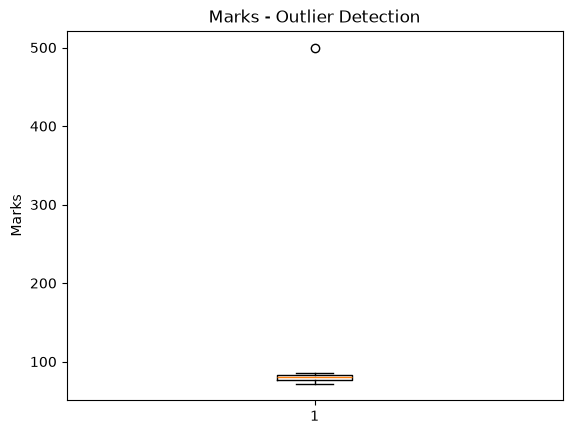

In [21]:
# 8. Box Plot દ્વારા Outliers સમજવા

# Box Plot માં સામાન્ય રીતે:
# - Box નો નીચેનો કિનારો: Q1
# - Box ની અંદરની લાઇન: Median
# - Box નો ઉપરનો કિનારો: Q3
# - Whiskers: નિયમ પ્રમાણે નક્કી થયેલી સીમા સુધીના Data
# - Whiskers ની બહારના Points: સંભવિત Outliers
# Python માં Box Plot બનાવવા માટે:

import matplotlib.pyplot as plt

marks = [72, 75, 78, 80, 82, 85, 500]

plt.boxplot(marks)
plt.title("Marks - Outlier Detection")
plt.ylabel("Marks")
plt.show()

In [ ]:
# 9. Real-World Practical — Student Data Cleaning

import pandas as pd

data = {
    "StudentID": [101, 102, 103, 102, 104, 105, 106],
    "Name": ["Amit", "Neha", "Ravi", "Neha", "Pooja",
             "Karan", "Mira"],
    "Marks": [85, 92, 76, 92, 88, 67, 500],
    "Attendance": [90, 95, 80, 95, 85, 70, 98]
}

df = pd.DataFrame(data)

# Step 1: સંપૂર્ણ Duplicate Rows દૂર કરો
clean_df = df.drop_duplicates()

# Step 2: Marks માટે IQR ગણો
Q1 = clean_df["Marks"].quantile(0.25)
Q3 = clean_df["Marks"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Step 3: Outliers ને Flag કરો
clean_df["Potential_Outlier"] = (
    (clean_df["Marks"] < lower) |
    (clean_df["Marks"] > upper)
)

print(clean_df)

# અહીં Potential_Outlier Column માં True આવે તો તે Record માં Marks સંભવિત Outlier છે.

   StudentID   Name  Marks  Attendance  Potential_Outlier
0        101   Amit     85          90              False
1        102   Neha     92          95              False
2        103   Ravi     76          80              False
4        104  Pooja     88          85              False
5        105  Karan     67          70              False
6        106   Mira    500          98               True


In [ ]:
# 11. Practical Assignment
# Assignment Checklist
# 0/7 પૂર્ણ

# [ ] `duplicated()` વડે તમામ Duplicate Rows શોધો.
# [ ] `drop_duplicates()` વડે સંપૂર્ણ Duplicate Rows દૂર કરો.
# [ ] `subset=['StudentID']` નો ઉપયોગ કરીને StudentID આધારિત Duplicate શોધો.
# [ ] Marks Column માટે Q1, Q3 અને IQR ગણો.
# [ ] IQR Bounds વડે સંભવિત Outliers ઓળખો.
# [ ] Z-score વડે |Z| > 3 ધરાવતી Values શોધો.
# [ ] Box Plot બનાવો અને પરિણામનું અર્થઘટન કરો.